In [29]:
"""Reproduce the Central Kalimantan AGC workflow with the Earth Engine Python API.

This still runs computations on Google Earth Engine; it is not an offline/local
replacement. Install earthengine-api, numpy, and matplotlib, then authenticate.
"""

import ee
import numpy as np
import matplotlib.pyplot as plt

# ee.Authenticate() # need to rerun every week 
ee.Initialize(project="esoteric-realm-483817-u5")

In [37]:
# -----------------------------------------------------------------------------
# 1. Study area
# -----------------------------------------------------------------------------

gaul = ee.FeatureCollection("FAO/GAUL_SIMPLIFIED_500m/2015/level1")
roi = (gaul
       .filter(ee.Filter.eq("ADM0_NAME", "Indonesia"))
       .filter(ee.Filter.eq("ADM1_NAME", "Sulawesi Tengah")))
roi_geom = roi.geometry()

In [36]:
# -----------------------------------------------------------------------------
# 2. Reference aboveground carbon density (Mg C/ha)
# -----------------------------------------------------------------------------

agc = (ee.ImageCollection("NASA/ORNL/biomass_carbon_density/v1")
       .select("agb", "agb_uncertainty")
       .first()
       .clipToCollection(roi))

print("Bands:", agc.bandNames().getInfo())

Bands: ['agb', 'agb_uncertainty']


In [38]:
# -----------------------------------------------------------------------------
# 3. Predictor builder
# -----------------------------------------------------------------------------

def build_predictors(start_date, end_date):
    vi = (ee.ImageCollection("MODIS/061/MOD13Q1")
          .select(["NDVI", "EVI"])
          .filterDate(start_date, end_date)
          .map(lambda img: img.multiply(0.0001).copyProperties(
              img, img.propertyNames()))
          .median())

    def scale_lai_fpar(img):
        lai = img.select("Lai_500m").multiply(0.1).rename("Lai_500m")
        fpar = img.select("Fpar_500m").multiply(0.01).rename("Fpar_500m")
        return lai.addBands(fpar).copyProperties(img, img.propertyNames())

    lai_fpar = (ee.ImageCollection("MODIS/061/MOD15A2H")
                .select(["Lai_500m", "Fpar_500m"])
                .filterDate(start_date, end_date)
                .map(scale_lai_fpar)
                .median())

    landcover = (ee.ImageCollection("MODIS/061/MCD12Q1")
                 .select("LC_Type1")
                 .filterDate(start_date, end_date)
                 .mode())

    elevation = ee.Image("USGS/GTOPO30").select("elevation")
    return ee.Image.cat([vi, lai_fpar, landcover, elevation]).clipToCollection(roi)

print("Earth Engine initialized")

print("ROI feature count:", roi.size().getInfo())

predictors2010 = build_predictors("2010-01-01", "2011-01-01")
print("Predictor bands:", predictors2010.bandNames().getInfo())

Earth Engine initialized
ROI feature count: 1
Predictor bands: ['NDVI', 'EVI', 'Lai_500m', 'Fpar_500m', 'LC_Type1', 'elevation']


Valid paired samples: 14,493
AGC (Mg C/ha): median=97.65, 5th–95th percentile=29.23–148.16
AGC share at or above its 95th-percentile threshold (148.16): 5.0%
NDVI: median=0.816, 5th–95th percentile=0.540–0.880


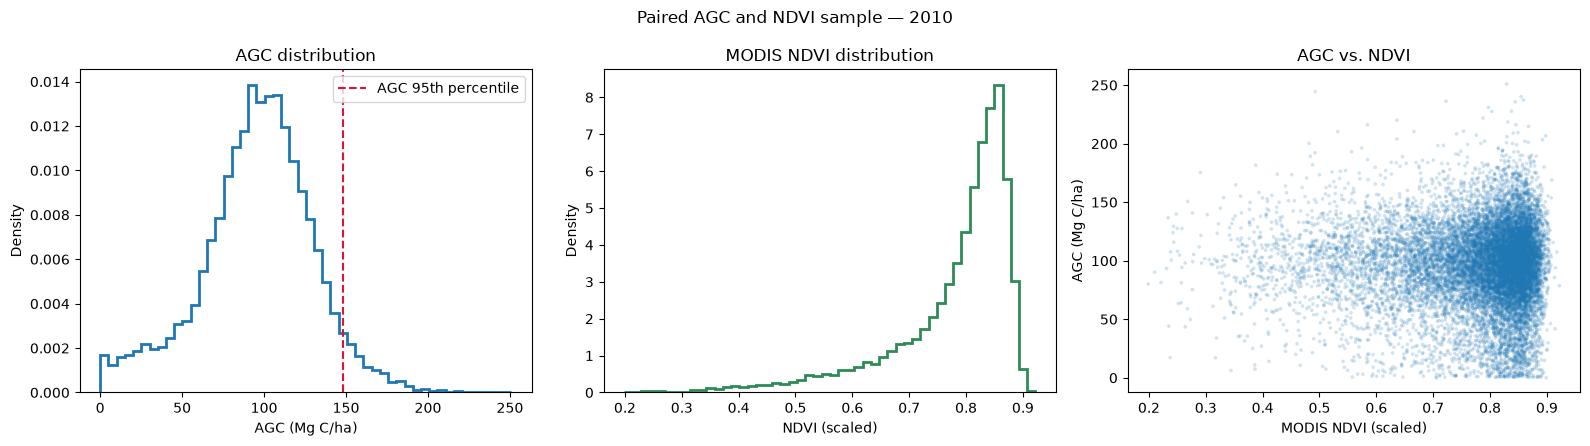

In [39]:
# Append this after `predictors2010` has been created.
# Samples AGC and NDVI on the same valid pixels at 500 m.

sample_image = (agc.select("agb").rename("AGC_MgC_ha")
                .addBands(predictors2010.select("NDVI")))
samples = sample_image.sample(
    region=roi_geom,
    scale=500,
    numPixels=15000,
    seed=42,
    dropNulls=True,
    geometries=False,
    tileScale=4,
)

agc_values = np.asarray(samples.aggregate_array("AGC_MgC_ha").getInfo(), dtype=float)
ndvi_values = np.asarray(samples.aggregate_array("NDVI").getInfo(), dtype=float)
valid = np.isfinite(agc_values) & np.isfinite(ndvi_values)
agc_values, ndvi_values = agc_values[valid], ndvi_values[valid]

if len(agc_values) == 0:
    raise ValueError("No valid AGC–NDVI samples. Check the ROI, dates, and image masks.")

# Summaries, including the empirical upper-tail threshold and share.
agc_p95 = np.percentile(agc_values, 95)
print(f"Valid paired samples: {len(agc_values):,}")
print(f"AGC (Mg C/ha): median={np.median(agc_values):.2f}, "
      f"5th–95th percentile={np.percentile(agc_values, 5):.2f}–{agc_p95:.2f}")
print(f"AGC share at or above its 95th-percentile threshold ({agc_p95:.2f}): "
      f"{np.mean(agc_values >= agc_p95):.1%}")
print(f"NDVI: median={np.median(ndvi_values):.3f}, "
      f"5th–95th percentile={np.percentile(ndvi_values, 5):.3f}–"
      f"{np.percentile(ndvi_values, 95):.3f}")

# Density histograms show the target and main input distributions; the scatter
# shows how AGC varies with NDVI. Use paired samples for all three plots.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].hist(agc_values, bins=50, density=True, histtype="step", linewidth=2)
axes[0].axvline(agc_p95, color="crimson", linestyle="--", label="AGC 95th percentile")
axes[0].set(title="AGC distribution", xlabel="AGC (Mg C/ha)", ylabel="Density")
axes[0].legend()

axes[1].hist(ndvi_values, bins=50, density=True, histtype="step", linewidth=2,
             color="seagreen")
axes[1].set(title="MODIS NDVI distribution", xlabel="NDVI (scaled)", ylabel="Density")

axes[2].scatter(ndvi_values, agc_values, s=7, alpha=0.2, edgecolors="none")
axes[2].set(title="AGC vs. NDVI", xlabel="MODIS NDVI (scaled)",
            ylabel="AGC (Mg C/ha)")

fig.suptitle("Paired AGC and NDVI sample — 2010")
fig.tight_layout()
plt.show()
